   loan_id  age  no_of_dependents      education self_employed  income_annum  \
0        1   34                 0   Not Graduate            No       6008000   
1        2   56                 4       Graduate           Yes       4624000   
2        3   37                 1       Graduate           Yes       5447000   
3        4   48                 5   Not Graduate           Yes       7334000   
4        5   31                 2   Not Graduate            No       7675000   

   loan_amount  loan_term  cibil_score  residential_assets_value  ...  \
0     21933000          8          322                   3095000  ...   
1     16967000          4          525                   9079000  ...   
2     19673000         11          300                  12157000  ...   
3     25076000         17          836                   4520000  ...   
4     31290000         20          810                  12984000  ...   

   loan_purpose  property_area  credit_history_years existing_loans  \
0     Edu

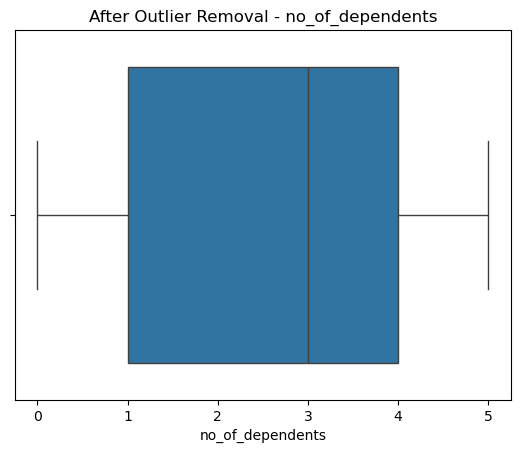

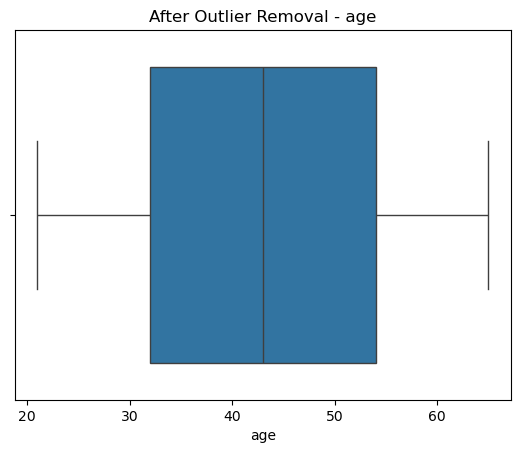

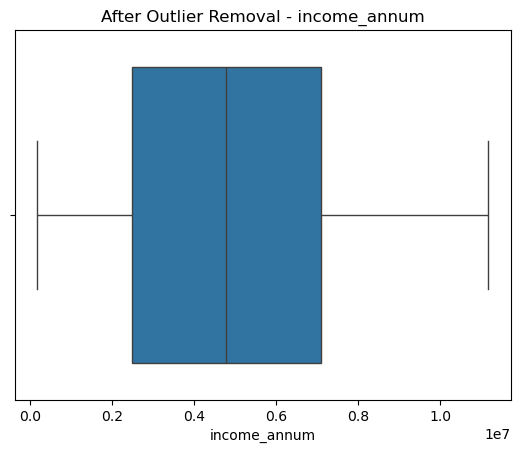

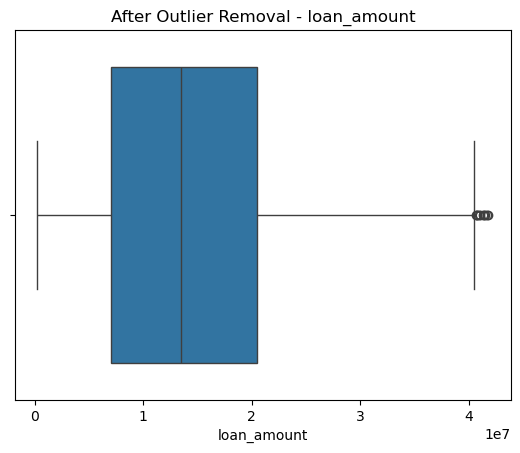

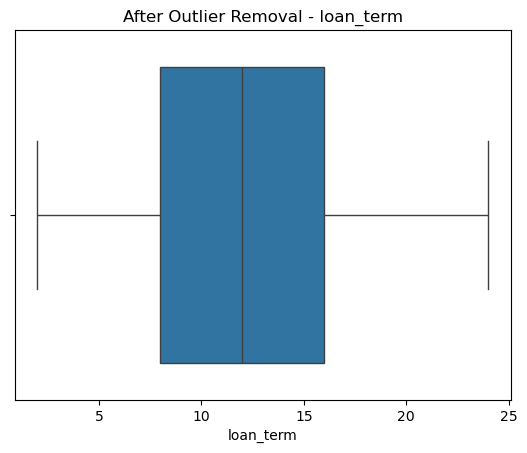

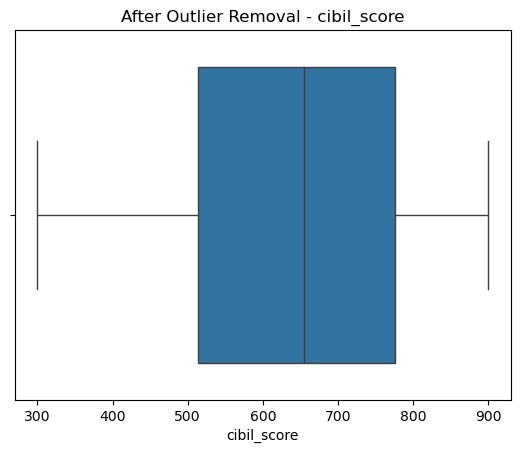

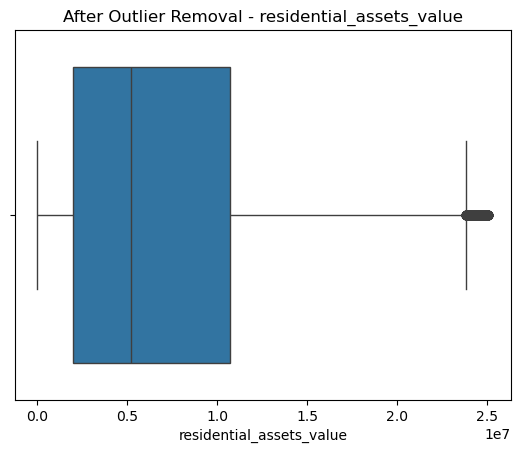

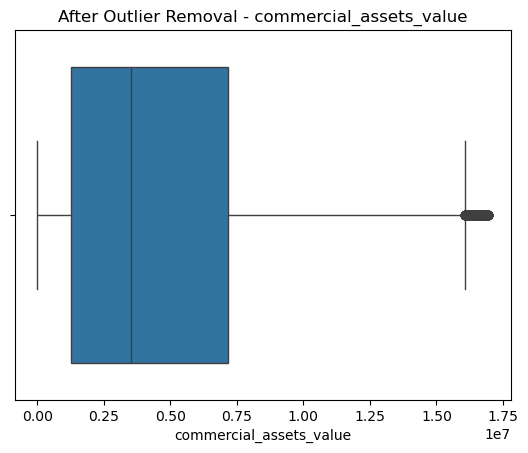

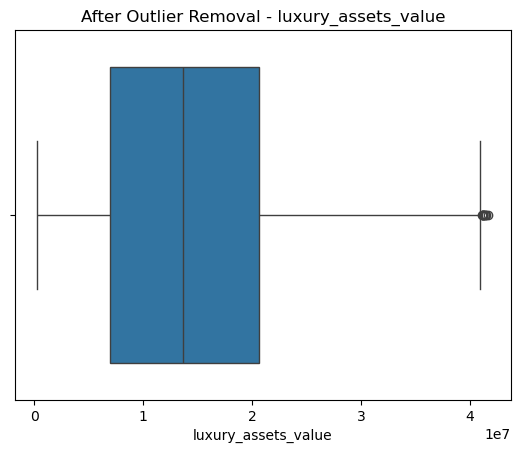

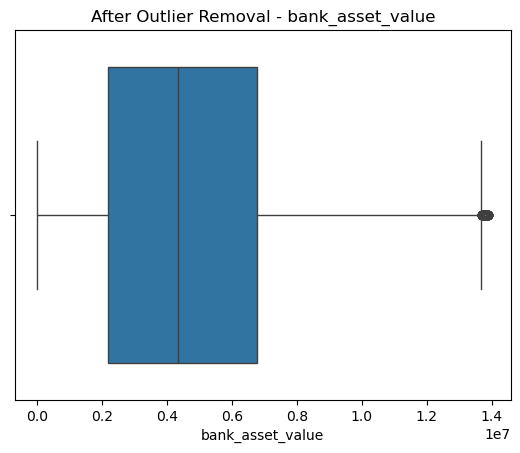

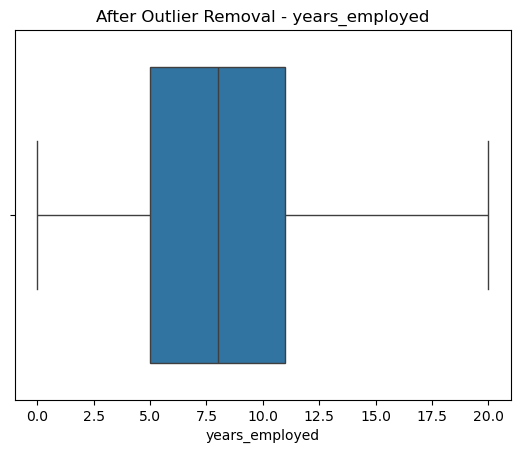

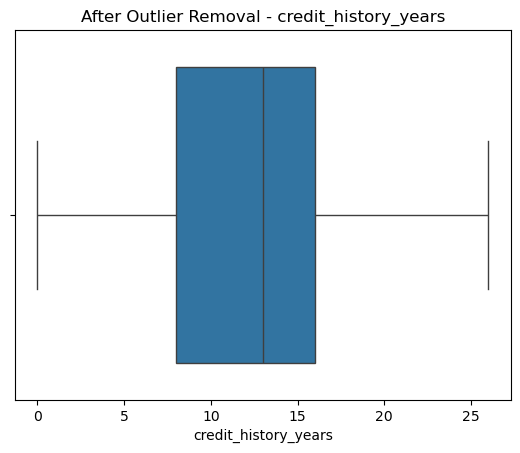

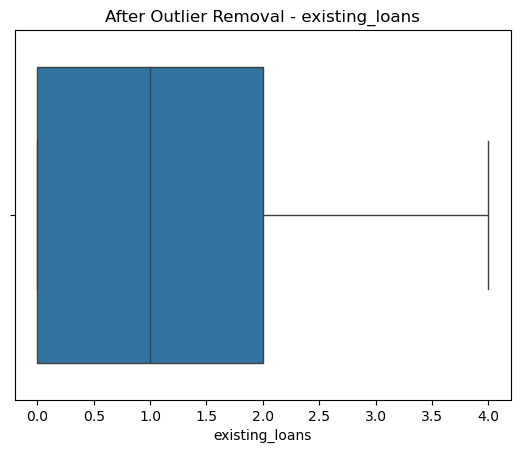

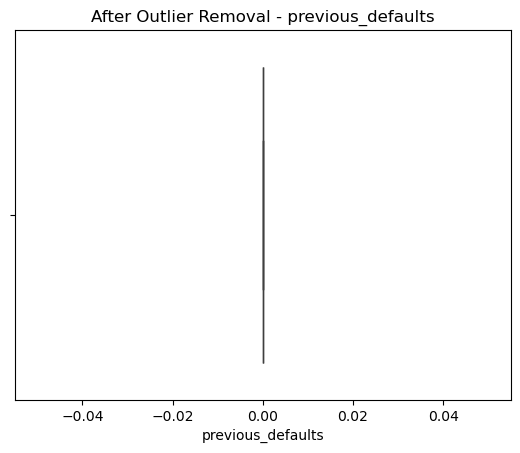

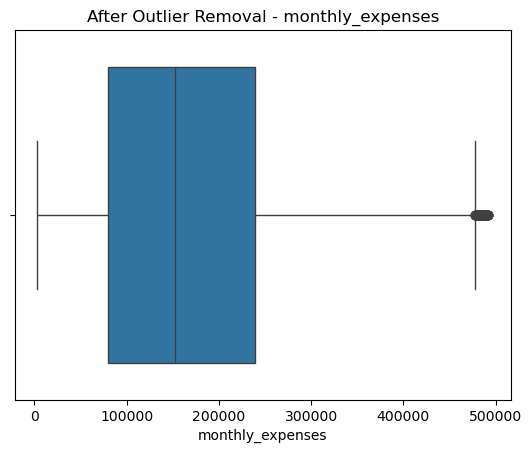

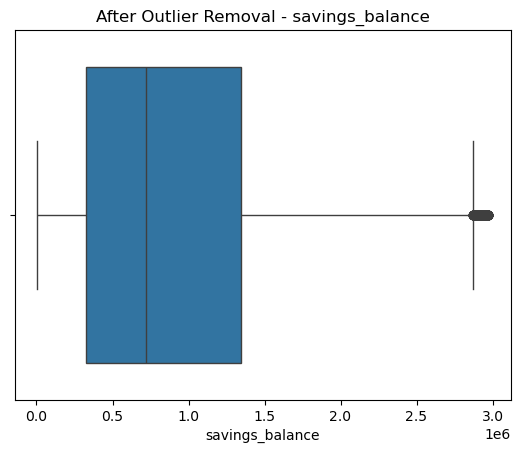

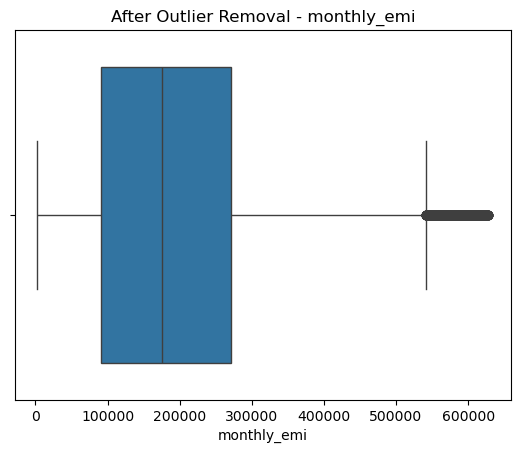

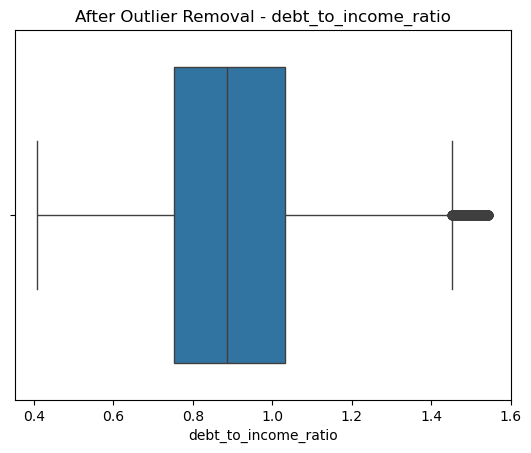

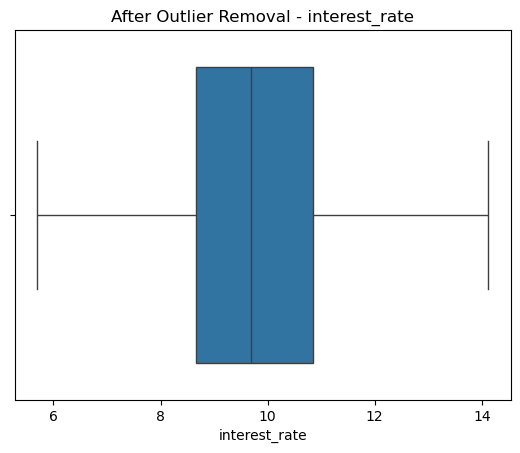

Before removing outliers:
(100000, 25)
After removing outlers:
(65467, 25)


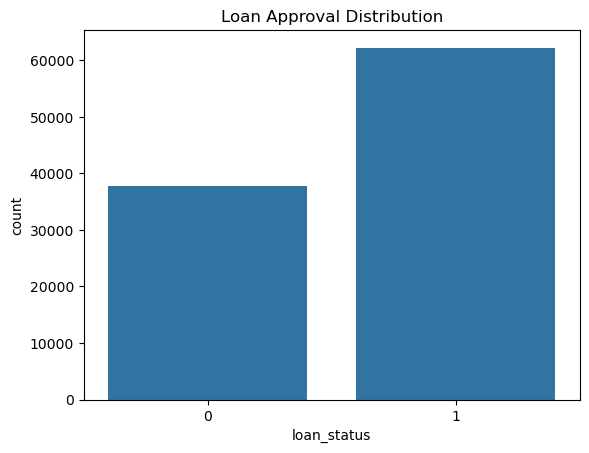

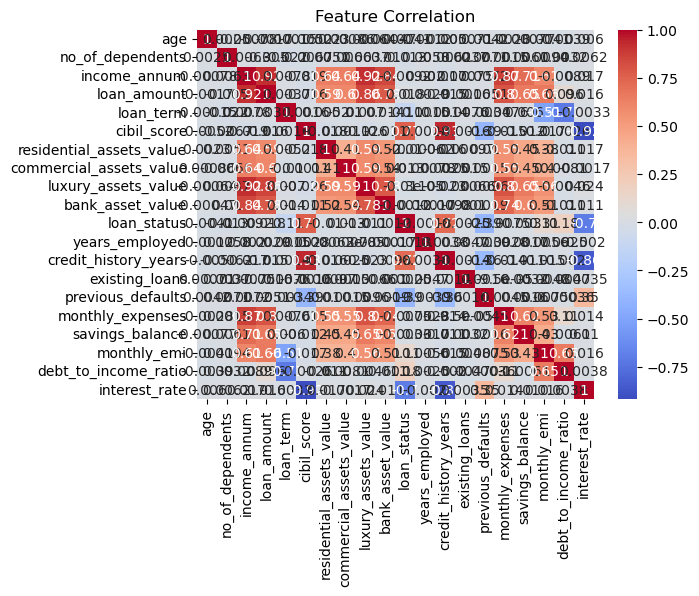

(80000, 24)
(20000, 24)

 Logistic Regression
Accuracy: 0.9349
              precision    recall  f1-score   support

    approved       0.94      0.95      0.95     12451
    rejected       0.92      0.91      0.91      7549

    accuracy                           0.93     20000
   macro avg       0.93      0.93      0.93     20000
weighted avg       0.93      0.93      0.93     20000


 Decision Tree
Accuracy: 0.96025
              precision    recall  f1-score   support

    approved       0.97      0.97      0.97     12451
    rejected       0.95      0.95      0.95      7549

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000


 Random Forest
Accuracy: 0.97505
              precision    recall  f1-score   support

    approved       0.98      0.98      0.98     12451
    rejected       0.97      0.97      0.97      7549

    accuracy                           0.98     200

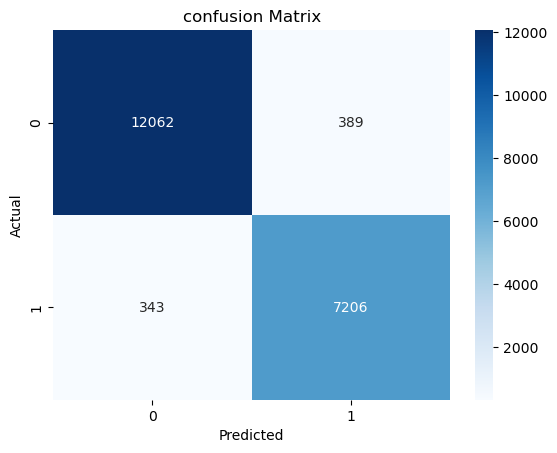

Loan Status:Rejected


['classification_model.pkl']

In [ ]:
# import libraries

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

# Load the dataset

df = pd.read_csv(r"C:\Users\bakki\Downloads\loan_approval_100k_26_columns.csv")
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

df.columns=df.columns.str.strip()
print(df.columns)
print(df.columns.tolist())


# Data CLeaning

df['loan_status'] = (
    df['loan_status']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Convert target into numerical values

df['loan_status'] = df['loan_status'].map({
    'approved': 1,
    'rejected': 0
})

# Check target values
print(df['loan_status'].value_counts())
print(df['loan_status'].isnull().sum())

# Remove unwanted column
df = df.drop("loan_id", axis=1)

# Separate X and y AFTER encoding

X = df.drop('loan_status', axis=1)
y = df['loan_status']

print(X.head())
print(y.head())


# Outlier analysis

numerical_cols = [
    "no_of_dependents",
    "age",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value",
    "years_employed",
    "credit_history_years",
    "existing_loans",
    "previous_defaults",
    "monthly_expenses",
    "savings_balance",
    "monthly_emi",
    "debt_to_income_ratio",
    "interest_rate"
]
for col in numerical_cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(col)
    print("Lower limit:",lower)
    print("Upper limit:",upper)


    df_clean = df.copy()

for col in numerical_cols:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_clean = df_clean[
        (df_clean[col] >= lower) &
        (df_clean[col] <= upper)
    ]

print("Original shape:", df.shape)
print("After removing outliers:", df_clean.shape)


import seaborn as sns
import matplotlib.pyplot as plt
for col in numerical_cols:

    sns.boxplot(x=df_clean[col])

    plt.title(f"After Outlier Removal - {col}")
    plt.show()

print("Before removing outliers:")
print(df.shape)
print("After removing outlers:")
print(df_clean.shape)


# Exploratory data analysis
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=df,
              x="loan_status")
plt.title("Loan Approval Distribution")
plt.show()

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation")
plt.show()

# Data Preprocessing
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

# Create Pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import(
StandardScaler,OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# Train-Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

# Build Base Model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
accuracy_score,
classification_report,
confusion_matrix,
precision_score,
recall_score,
f1_score,
roc_auc_score)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42
        
    )
}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test,y_pred))


    # Cross validation

    from sklearn.model_selection import cross_val_score
base_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

scores = cross_val_score(
    base_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross Validation Scores:", scores)

print("Average CV Score:", scores.mean())

# Create ML Pipeline
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

print("Pipeline Accuracy:",
      accuracy_score(y_test, y_pred))

# Hyper parameter tuning
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [50],
    "classifier__max_depth": [5, 10],
    "classifier__min_samples_split": [2]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)


import joblib

# Get the best trained pipeline
best_model = grid_search.best_estimator_

# Save the model
joblib.dump(
    best_model,
    "classification_model.pkl"
)

print("Model saved successfully!")

# Ensemble algorithms
from sklearn.ensemble import(
    RandomForestClassifier,
    GradientBoostingClassifier
)


ensemble_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

for name, model in ensemble_models.items():

    ensemble_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    ensemble_pipeline.fit(X_train, y_train)

    pred = ensemble_pipeline.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    
    print(classification_report(y_test,y_pred))

    # Feature Importance
    
rf = grid_search.best_estimator_.named_steps["classifier"]

feature_names = (
    grid_search.best_estimator_
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

# Final model evaluation

best_model = grid_search.best_estimator_

final_pred = best_model.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, final_pred))

print("\nClassification Report:")
print(classification_report(y_test, final_pred))

# Confusion Matrix
cm=confusion_matrix(y_test,final_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("confusion Matrix")
plt.show()

# Make a prediction

sample_data=X_test.iloc[[0]]
prediction=best_model.predict(sample_data)
if prediction[0]==1:
    print("Loan Status: Approved")
else:
    print("Loan Status:Rejected")


import joblib

joblib.dump(best_model, "classification_model.pkl")
